# WASP-21 b: radio del planeta a partir de la curva de luz de TESS

**Objetivo.** Detectar el tránsito de WASP-21 b en fotometría de TESS, medir su periodo y estimar el radio del planeta.

**Métodos.** Descarga con [Lightkurve](https://lightkurve.github.io/lightkurve/) → aplanado de la curva de luz y eliminación de valores atípicos → periodograma BLS (*Box Least Squares*) → curva plegada → radio a partir de la profundidad del tránsito, $R_p = \sqrt{\delta}\,R_\star$.

Requiere conexión a internet (descarga desde MAST).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
%matplotlib inline

## 1. Descarga de las curvas de luz

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 56,2022,QLP,200,436478932,0.0


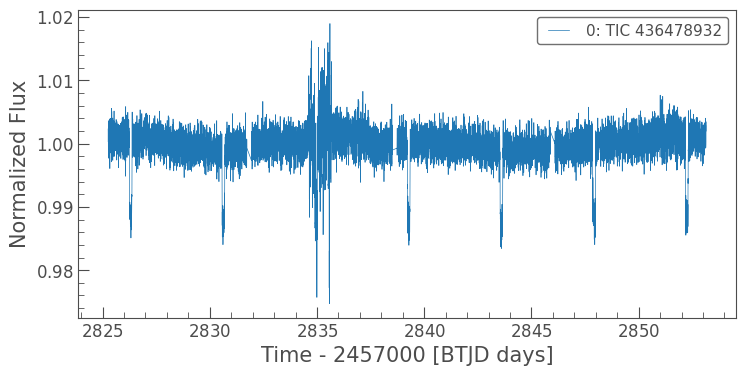

In [ ]:
search_result = lk.search_lightcurve('WASP-21 b')[2]  # índice 2: ajusta según los resultados disponibles en MAST
lc_collection = search_result.download_all()
lc_collection.plot()
search_result

## 2. Aplanado y limpieza

Se unen los sectores (`stitch`), se elimina la tendencia de baja frecuencia con un filtro Savitzky-Golay (`flatten`) y se descartan outliers.

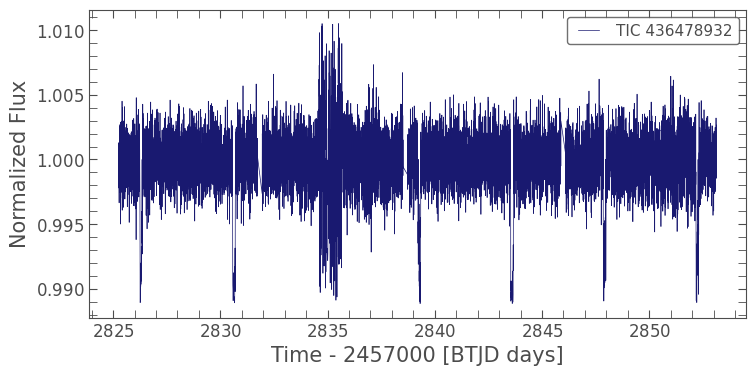

In [ ]:
lc = lc_collection.stitch().flatten(window_length=901).remove_outliers()
#lc = lc_collection.flatten(window_length=901).remove_outliers()
lc.plot(color='midnightblue')
plt.tick_params(axis='both', which='both', bottom=True, top=True, left=True, right=True, direction='in', length=6,grid_linestyle='--')
plt.show()

## 3. Periodograma BLS

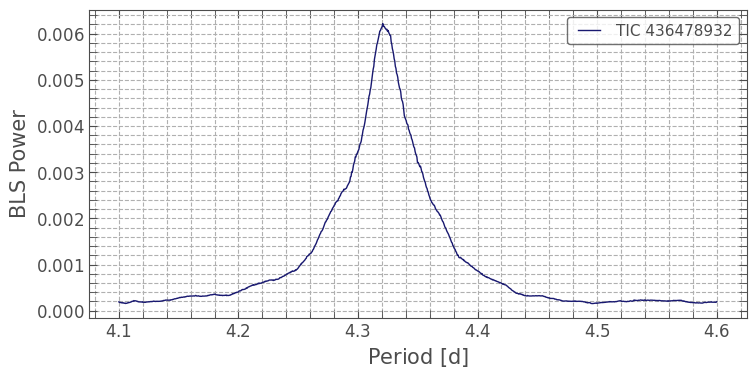

In [ ]:
import numpy as np
# Create array of periods to search
period = np.linspace(4.1, 4.6, 1000)
# Create a BLSPeriodogram
bls = lc.to_periodogram(method='bls', period=period, frequency_factor=500)
bls.plot(color='midnightblue',linewidth=1)
plt.tick_params(axis='both', which='both', bottom=True, top=True, left=True, right=True, direction='in', length=6,grid_linestyle='--')
plt.grid('x','both')
plt.show()

In [ ]:
planet_b_period = bls.period_at_max_power
planet_b_t0 = bls.transit_time_at_max_power
planet_b_dur = bls.duration_at_max_power

# Check the value for period
planet_b_period

<Quantity 4.32072072 d>

## 4. Curva de luz plegada

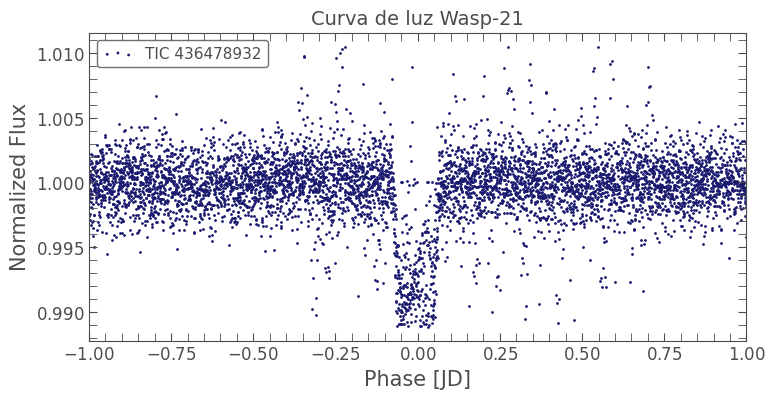

In [ ]:
ax = lc.fold(period=planet_b_period, epoch_time=planet_b_t0).scatter(color='midnightblue')
ax.set_xlim(-1, 1)
plt.tick_params(axis='both', which='both', bottom=True, top=True, left=True, right=True, direction='in', length=6,grid_linestyle='--')
plt.title("Curva de luz Wasp-21",fontsize=14);

## 5. Radio del planeta

La profundidad del tránsito es $\delta = 1 - F_{min}$ y $R_p = \sqrt{\delta}\,R_\star$, con $R_\star = 1.136\,R_\odot$ (Chen).

> **Nota:** usar el mínimo del flujo (`min(lc.flux)`) es una estimación gruesa, sensible al ruido de un solo punto. Una mejora natural es medir la profundidad como la mediana del flujo dentro del tránsito.

In [ ]:
F=min(lc.flux)
flux=F.value

In [ ]:
Rsol=6.95700e8
Rs=1.136*Rsol #Radio estrella \Chen
#Rs=1.3475700*Rsol #Radio estrella \\TICv8 - Alderson

delta=np.abs(1-flux)
Rp=(np.sqrt(delta))*Rs
RJ=69911000 #m

#R_real=1.07*RJ #\\Bouchy
R_real=1.15*RJ #\\Alderson

print(f"El radio del planeta es: {Rp/RJ} Rj")
print("El error relativo es: ", np.abs((R_real-Rp)/(R_real))*100)


El radio del planeta es: 1.1934827719549104 Rj
El error relativo es:  3.7811106047748106


## Conclusiones

- BLS recupera el periodo orbital en torno a 4.3 d, consistente con la velocidad radial.
- El radio estimado es **≈ 1.19 R<sub>J</sub>**, con ~3.8 % de diferencia frente a 1.15 R<sub>J</sub> (Alderson et al. 2020).
- Combinado con la masa del notebook 01 (~0.3 M<sub>J</sub>), WASP-21 b es un planeta de baja densidad tipo "Saturno caliente".